# 2024-2025 plot

## Import modules

In [1]:
import numpy as np
from scipy import signal
from obspy.signal import filter
import matplotlib.pyplot as plt
import os
from glob import glob
import xarray as xr
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from tqdm import tqdm
import matplotlib.dates as mdates

## Create folders

In [2]:
plot_dir = '../../plots/FBG_strain'
if not os.path.exists(plot_dir):
    os.makedirs(plot_dir)

## Processing and plotting

### Importing data

In [3]:
ncfiles = glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG*nc')# +glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_2025.02*nc')
ncfiles.sort()
for i, file in enumerate(tqdm(ncfiles)) : 
    ds_24 = xr.open_dataset(file)
    ds_24 = ds_24.drop_vars(['relative_Time', 'Temperature_calibration','Strain_calibration'])
    ds_24 = ds_24.sortby('Time')
    ds_24 = ds_24.sel(Channel=2)
    #ds_24 = ds_24.Wavelength_nm.resample(Time='1h').mean()
    if i == 0:
        ds_out_2024 = ds_24
        continue
    ds_out_2024 = xr.concat([ds_out_2024, ds_24], dim='Time')

100%|██████████| 347/347 [03:36<00:00,  1.61it/s]


### A bit of cleaning

In [4]:
ds_out_2024 = ds_out_2024.sortby('Time')
ds_out_2024 = ds_out_2024.drop_duplicates('Time')
ds_out_2024 = ds_out_2024.reindex(Time=np.arange(ds_out_2024.Time.values.min(), ds_out_2024.Time.values.max()+1, 2, dtype='datetime64[s]'),
                                     method='nearest', tolerance=np.timedelta64(2, 's'))

/tmp/ipykernel_404972/583309364.py:3: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds_out_2024 = ds_out_2024.reindex(Time=np.arange(ds_out_2024.Time.values.min(), ds_out_2024.Time.values.max()+1, 2, dtype='datetime64[s]'),


### Import temperature

In [5]:
ds_temp_2024 = xr.open_dataset('/home/geophysic/jgovoort/fbg_gunnuvher/fbg_data_r/gunnvher_channel_1_fbg_cleaned_1h.nc')

In [6]:
ds_temp_2024['Wavelength_nm_shift'] = (ds_temp_2024.Wavelength_nm - ds_temp_2024.Wavelength_nm.isel(Time=0))
ds_temp_2024['median_wavelength'] = ds_temp_2024.Wavelength_nm_shift.median('FBG') - .2
ds_temp_2024['std_wavelength'] = ds_temp_2024.Wavelength_nm_shift.std('FBG')

In [7]:
ds_out_2024['Wavelength_nm_shift'] = (ds_out_2024.Wavelength_nm - ds_out_2024.Wavelength_nm.isel(Time=0))
ds_out_2024['mean_wavelength'] = ds_out_2024.Wavelength_nm_shift.mean('FBG')
ds_out_2024['std_wavelength'] = ds_out_2024.Wavelength_nm_shift.std('FBG')

### Plotting

In [8]:
arrow = dict(arrowstyle = "<->", ec='k')
bbox = dict(boxstyle='round', fc= 'lightgrey')

In [9]:
fig = plt.figure(figsize=(15,7))

ax = plt.subplot2grid((3,2), (0,0), rowspan=2, colspan=2)
for i in tqdm(range(9)) :
    dwav = ds_out_2024.Wavelength_nm_shift.isel(FBG=i) + i*.1
    if i == 0:
        dwav.plot(ax=ax, c='k', alpha=0.75, label='SP-3.x')
    else :
        dwav.plot(ax=ax, c='k', alpha=0.75)
(ds_temp_2024.median_wavelength - ds_temp_2024.median_wavelength.isel(Time=0) - .1).plot(ax=ax, color='blue', label='T-2.xx', alpha=.75)
#ax.fill_between(ds_temp_2024.Time.values, ds_temp_2024.median_wavelength - ds_temp_2024.std_wavelength,
#                 ds_temp_2024.median_wavelength + ds_temp_2024.std_wavelength, color='orange', alpha=0.5, label='Temperature-induced wavelength shift (nm) ± std')
ax.grid(ls=':', c='lightgrey')
ax.set_yticks(np.arange(-.3,.6, .2, dtype='float32'))
ax.set_xlabel('Time'), ax.set_ylabel('Horizontal strain-pads profile\n $\Delta \lambda$(nm)')
ax.set_xlim(ds_out_2024.Time.values.min(), ds_out_2024.Time.values.max())
ax.set_ylim(-.3, .7)
ax.legend(loc='upper right')
ax.text(np.datetime64('2025-07-20T00:00:00'), .6, 'A', fontsize=14, fontweight='bold', c='k')
ax1 = plt.subplot2grid((3,2), (2,0), rowspan=1, colspan=1)
#strain_rate = ds_out_2024.Wavelength_nm_shift.sel(FBG=3, Time=slice('2024-10-18T22', '2024-10-21T02')).diff('Time')/2
strain_rate = ds_out_2024.Wavelength_nm_shift.sel(FBG=3,Time=slice('2024-10-23', '2024-10-26')).diff('Time')/2 * 1000
#cycle_6h = signal.detrend(strain_rate)
Time_cycle = ds_out_2024.Time.sel(Time=slice('2024-10-23', '2024-10-26'))[:-1]
ax1.plot(Time_cycle, strain_rate, label='FBG 3', c='k', alpha=0.75)
ax1.set_xlim(np.datetime64('2024-10-24T00:00:00'), np.datetime64('2024-10-25T00:00:00'))
ax1.set_xticks(np.arange(np.datetime64('2024-10-24T00:00:00'), 
                        np.datetime64('2024-10-25T00:00:00')+1, np.timedelta64(6, 'h')))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
ax1.grid(ls=':', c='lightgrey')
ax1.set_xlabel('Time'), ax1.set_ylabel('Strain rate (µ$\epsilon$/s)')
ax1.text(np.datetime64('2024-10-24T01:00:00'), .17, 'B', fontsize=14, fontweight='bold', c='k')
ax1b = ax1.twinx()
ax1b.set_xlim(np.datetime64('2024-10-24T00:00:00'), np.datetime64('2024-10-25T00:00:00'))
ax1b.set_ylim(.2-.03, .2+.02)
ax1b.tick_params(axis='y', right=False, left=False)
ax1.annotate('', xy=(np.datetime64('2024-10-24T06:50'), .12), xytext=(np.datetime64('2024-10-24T10:50'), .12),
             arrowprops = arrow, bbox=bbox)#plt.ylim(top=12)
ax1.annotate('3-hours cycle', xy=(np.datetime64('2024-10-24T08:50'), .12),
             textcoords='offset points', xytext=(0,10), ha='center', fontsize=10, bbox=bbox)
ax.indicate_inset_zoom(ax1b, edgecolor="red")
ax1b.set_yticks([],[])

ax2 = plt.subplot2grid((3,2), (2,1), rowspan=1, colspan=1)

cycle_15min = signal.detrend(ds_out_2024.Wavelength_nm_shift.sel(FBG=3, Time=slice('2025-01-03T16', '2025-01-04T04')))
Time_cycle = ds_out_2024.Time.sel(Time=slice('2025-01-03T16', '2025-01-04T04')) 
cycle_15min = signal.windows.tukey(len(cycle_15min), alpha=.1) * filter.highpass(cycle_15min, df=1/2, freq=1e-4) *1000
ax2.plot(Time_cycle, cycle_15min, label='FBG 3', c='k', alpha=0.75)
ax2.set_xlim(np.datetime64('2025-01-03T20:00:00'), np.datetime64('2025-01-04T02:00:00'))
ax2.text(np.datetime64('2025-01-04T01:45'), .3, 'C', fontsize=14, fontweight='bold', c='k')
ax2.set_ylim(-3e-1, 4e-1)
ax2.grid(ls=':', c='lightgrey')
ax2.set_xlabel('Time'), ax2.set_ylabel('$\Delta \lambda$ (pm)')
ax2b = ax2.twinx()
ax2b.set_xlim(np.datetime64('2025-01-03T20:00:00'), np.datetime64('2025-01-04T02:00:00'))
ax2b.set_ylim(.09-.02, .09+.02)
ax2b.set_yticks([],[])

ax2.annotate('', xy=(np.datetime64('2025-01-03T23:49'), .27), xytext=(np.datetime64('2025-01-04T00:15'), .27),
             arrowprops = arrow, bbox=bbox)#plt.ylim(top=12)
ax2.annotate('15-min cycle', xy=(np.datetime64('2025-01-04T00'), .27),
             textcoords='offset points', xytext=(0,10), ha='center', fontsize=10, bbox=bbox)
ax2.set_xticks(np.arange(np.datetime64('2025-01-03T20:00:00'), np.datetime64('2025-01-04T02:00:00')+1, np.timedelta64(2, 'h')))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
ax.indicate_inset_zoom(ax2b, edgecolor="red")

plt.savefig(f'{plot_dir}/FBG_2024_strain_cycles.png', dpi=300, bbox_inches='tight')
plt.close()

  0%|          | 0/9 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:20<00:00,  2.33s/it]


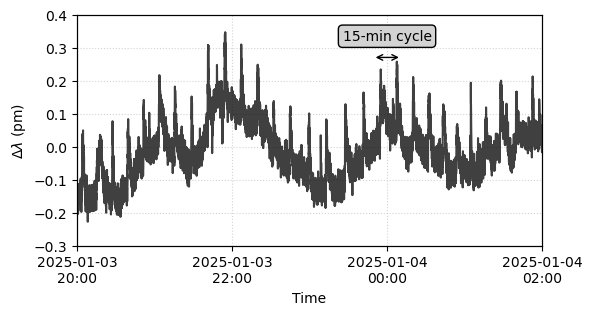

In [10]:
%matplotlib inline
fig, ax2 = plt.subplots(figsize=(6,3))
ax2.plot(Time_cycle, cycle_15min, label='FBG 3', c='k', alpha=0.75)
ax2.set_xlim(np.datetime64('2025-01-03T20:00:00'), np.datetime64('2025-01-04T02:00:00'))
ax2.set_ylim(-3e-1, 4e-1)
ax2.grid(ls=':', c='lightgrey')
ax2.set_xlabel('Time'), ax2.set_ylabel('$\Delta \lambda$ (pm)')
ax2b = ax2.twinx()
ax2b.set_xlim(np.datetime64('2025-01-03T20:00:00'), np.datetime64('2025-01-04T02:00:00'))
ax2b.set_ylim(.09-.02, .09+.02)
ax2b.set_yticks([],[])
arrow = dict(arrowstyle = "<->", ec='k')
bbox = dict(boxstyle='round', fc= 'lightgrey')
ax2.annotate('', xy=(np.datetime64('2025-01-03T23:49'), .27), xytext=(np.datetime64('2025-01-04T00:15'), .27),
             arrowprops = arrow, bbox=bbox)#plt.ylim(top=12)
ax2.annotate('15-min cycle', xy=(np.datetime64('2025-01-04T00'), .28),
             textcoords='offset points', xytext=(0,10), ha='center', fontsize=10, bbox=bbox)
ax2.set_xticks(np.arange(np.datetime64('2025-01-03T20:00:00'), np.datetime64('2025-01-04T02:00:00')+1, np.timedelta64(2, 'h')))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))

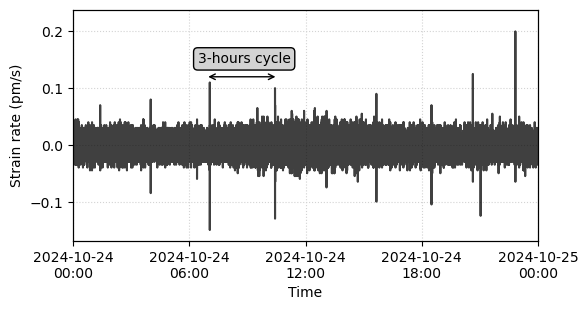

In [11]:
%matplotlib inline

fig, ax1 = plt.subplots(figsize=(6,3))
strain_rate = ds_out_2024.Wavelength_nm_shift.sel(FBG=3,Time=slice('2024-10-23', '2024-10-26')).diff('Time')/2 * 1000
#cycle_6h = signal.detrend(strain_rate)
Time_cycle = ds_out_2024.Time.sel(Time=slice('2024-10-23', '2024-10-26'))[:-1]
ax1.plot(Time_cycle, strain_rate, label='FBG 3', c='k', alpha=0.75)
ax1.set_xlim(np.datetime64('2024-10-24T00:00:00'), np.datetime64('2024-10-25T00:00:00'))
ax1.set_xticks(np.arange(np.datetime64('2024-10-24T00:00:00'), 
                        np.datetime64('2024-10-25T00:00:00')+1, np.timedelta64(6, 'h')))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
ax1.grid(ls=':', c='lightgrey')
ax1.set_xlabel('Time'), ax1.set_ylabel('Strain rate (pm/s)')
ax1b = ax1.twinx()
ax1b.set_xlim(np.datetime64('2024-10-24T00:00:00'), np.datetime64('2024-10-25T00:00:00'))
ax1b.set_ylim(.2-.03, .2+.02)
ax1b.tick_params(axis='y', right=False, left=False)
ax1.annotate('', xy=(np.datetime64('2024-10-24T06:50'), .12), xytext=(np.datetime64('2024-10-24T10:50'), .12),
             arrowprops = arrow, bbox=bbox)#plt.ylim(top=12)
ax1.annotate('3-hours cycle', xy=(np.datetime64('2024-10-24T08:50'), .12),
             textcoords='offset points', xytext=(0,10), ha='center', fontsize=10, bbox=bbox)
ax.indicate_inset_zoom(ax1b, edgecolor="red")
ax1b.set_yticks([],[])
plt.show()